In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# 1-2 Import and Explore
df=pd.read_csv("Retail_Sales_Data.csv")
df.head(2)

,Order_ID,Date,Region,Product_Category,Quantity,Sales_Amount
0,1001,2024-02-09,East,Toys,6,239.71
1,1002,2024-05-30,West,Toys,3,127.58


In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          1000 non-null   int64  
 1   Date              1000 non-null   object 
 2   Region            1000 non-null   object 
 3   Product_Category  1000 non-null   object 
 4   Quantity          1000 non-null   int64  
 5   Sales_Amount      992 non-null    float64
dtypes: float64(1), int64(2), object(3)
memory usage: 47.0+ KB


,Order_ID,Quantity,Sales_Amount
count,1000.000000,1000.000000,992.000000
mean,1500.500000,5.520000,873.616643
std,288.819436,2.861781,1447.655634
min,1001.000000,1.000000,4.460000
25%,1250.750000,3.000000,108.367500
50%,1500.500000,6.000000,270.295000
75%,1750.250000,8.000000,777.342500
max,2000.000000,10.000000,8244.940000


In [4]:
# 3. Relevant variables
df = df[["Region", "Product_Category", "Quantity", "Sales_Amount"]].dropna()

In [5]:
# 4. Total sales by region
region_sales = df.groupby("Region")["Sales_Amount"].sum().sort_values(ascending=False)
print(region_sales)


Region
West       207236.66
North      206928.57
South      197384.02
East       169450.95
Central     85627.51
Name: Sales_Amount, dtype: float64


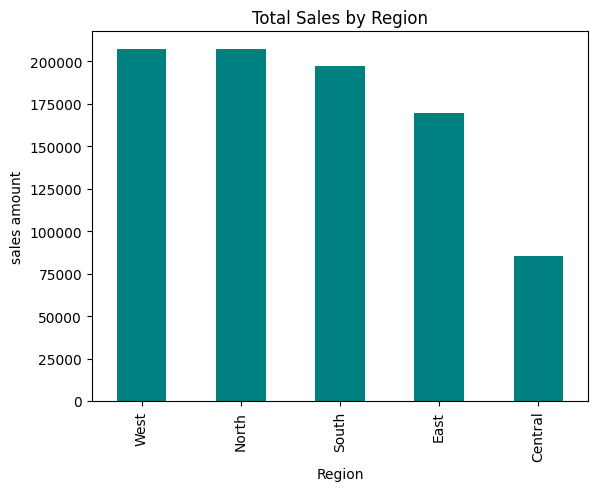

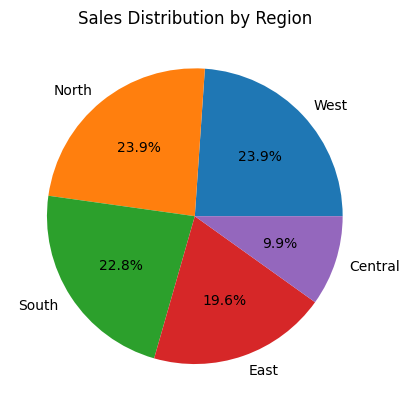

In [6]:
# 5. Visualization
region_sales.plot(kind="bar",color="teal",title="Total Sales by Region")
plt.ylabel("sales amount")
plt.show()

region_sales.plot(kind="pie",autopct="%1.1f%%",title="Sales Distribution by Region")
plt.ylabel("")
plt.show()


In [7]:
# 6. Top-performing regions
print("Top 3 regions:")
print(region_sales.head(3))


Top 3 regions:
Region
West     207236.66
North    206928.57
South    197384.02
Name: Sales_Amount, dtype: float64


In [8]:
# 7. Region and category aggregation
combo = df.groupby(["Region", "Product_Category"])["Sales_Amount"].sum().unstack()
print(combo)

Product_Category  Clothing  Electronics  Furniture  Groceries     Toys
Region                                                                
Central            8417.06     43151.04   27623.33    2554.69  3881.39
East              20073.54     92338.63   47629.89    4239.44  5169.45
North             24155.38    119952.36   44967.00    9100.86  8752.97
South             21476.14    103219.85   56761.44    8831.72  7094.87
West              23152.90    119623.68   45899.42   10611.39  7949.27


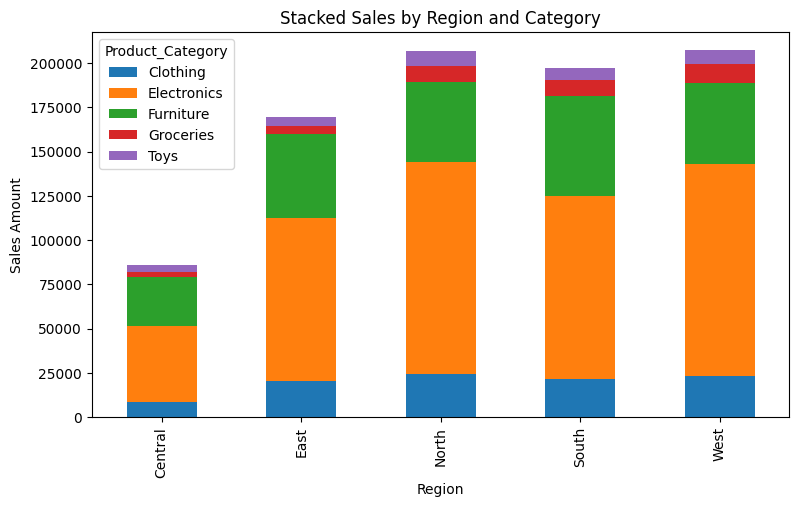

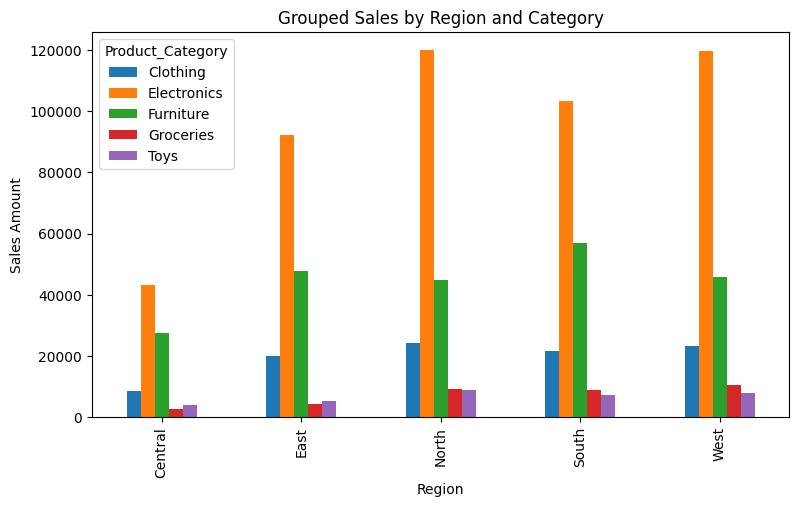

In [9]:
# 8. Stacked and grouped bar plots
combo.plot(kind="bar", stacked=True, figsize=(9, 5), title="Stacked Sales by Region and Category")
plt.ylabel("Sales Amount"); plt.show()
combo.plot(kind="bar", figsize=(9, 5), title="Grouped Sales by Region and Category")
plt.ylabel("Sales Amount"); plt.show() 